# T0 Set-up: reference solution

Questions T0.1, T0.2, T0.3 of [TASKS.md](../../TASKS.md). The code is in the scripts named below (run from the repository root); this notebook runs them, shows their figures and gives the answers. Every number quoted comes from `results/`.

In [1]:
import os
from pathlib import Path

import IPython.display as ipd

here = Path.cwd()
os.chdir(next(p for p in (here, *here.parents) if (p / "pyproject.toml").exists()))  # the repository root
FIGURES = Path("solutions/stage1_flash/figures")


def show(*names):
    """Display the figures of a question (GIF animates, else the PNG)."""
    for name in names:
        path = next(p for p in (FIGURES / f"{name}.gif", FIGURES / f"{name}.png") if p.exists())
        ipd.display(ipd.Image(filename=str(path), width=900))


## Run the scripts

Data sets are generated on first use and cached in `solutions/stage1_flash/data/`. The T0.2 timing was not re-measured in this build: `task0_timing.py --plot` redraws its figure from the stored numbers of `results/T0.json`.

In [2]:
!python solutions/stage1_flash/task0_setup.py
!python solutions/stage1_flash/task0_timing.py --plot
!python solutions/stage1_flash/task0_inspect.py

pytest: 165 passed, 10 deselected in 23.23s  (exit code 0, 25.5 s wall)
pytest installed by the analysis extra alone: False
versions: {'prob_reco_sbi': '0.1.0', 'python': '3.11.5', 'torch': '2.14.1+cpu', 'numpy': '2.4.6', 'h5py': '3.16.0', 'matplotlib': '3.11.2'}
results -> ./solutions/stage1_flash/results/T0.json


derived: {'cpu_median_time_50k_s': {'straight': 5.2247, 'absorb': 5.3978, 'absorb-scatter': 7.5348, 'full': 9.0613}, 'gpu_over_cpu_rate_50k': {'straight': 6.7, 'absorb': 7.4, 'absorb-scatter': 4.39, 'full': 4.19}, 'gpu_time_per_event_relative_to_straight_50k': {'straight': 1.0, 'absorb': 0.94, 'absorb-scatter': 2.2, 'full': 2.78}}


$ flashsim info solutions/stage1_flash/data/t0_cli_full_n10000_seed1.h5
file: solutions/stage1_flash/data/t0_cli_full_n10000_seed1.h5  (2.64 MB)
format version 1, 10000 events, 32 sensors

configuration (preset: full):
  geometry:   R = 1 m, 32 sensors of 0.1 m (photocoverage 0.509)
  light:      Y = 1000 photons/MeV (poisson), c_n = 0.2 m/ns
  absorption: lambda_a = 1.5 m; scattering: lambda_s = 2 m; reflection: rho = 0.5 (diffuse)
  readout:    efficiency 1, jitter 1 ns, dark rate 0 Hz in [0, 100] ns
  prior:      vertex uniform in r <= 1 m; energy uniform in [0.5, 5] MeV; t0 uniform in [0, 10] ns
  transport:  at most 80 interactions per photon

provenance:
  seed: 1
  photons_per_chunk: 2097152
  n_chunks: 14
  first_event_id: 0
  save_hits: False
  save_tracks: 0
  track_photons: 100
  device: cpu
  device_name: x86_64
  torch_threads: 16
  package_version: 0.1.0
  git_commit: feaeef75691034de60bb6cf59885a78cbecd0fd2-dirty
  python_version: 3.11.5
  numpy_version: 2.4.6
  torch_ve


optional groups (1000 events, --save-hits --save-tracks 3 --track-photons 100):
  /hits/event_id                   [896499]     int64    
  /hits/is_noise                   [896499]     bool     
  /hits/n_reflect                  [896499]     int32    
  /hits/n_scatter                  [896499]     int32    
  /hits/path_length                [896499]     float32  m
  /hits/sensor                     [896499]     int32    
  /hits/time                       [896499]     float32  ns
  /tracks/event_id                 [300]        int64    
  /tracks/kind                     [770]        int8     
  /tracks/offsets                  [301]        int64    
  /tracks/path_length              [770]        float32  m
  /tracks/photon                   [300]        int32    
  /tracks/x                        [770]        float32  m
  /tracks/y                        [770]        float32  m


## T0.1 Set-up

The fast test suite ends with `165 passed, 10 deselected`; our run took 22 s (24 s wall) on the CPU with 16 torch
threads, Python 3.11.5, torch 2.14.1+cpu, numpy 2.4.6 and h5py 3.16.0.

```bash
git clone https://github.com/ArseniiGav/prob-reco-sbi.git && cd prob-reco-sbi
python3 -m venv .venv && source .venv/bin/activate
python -m pip install --upgrade pip
python -m pip install -e ".[analysis,dev]"
python -m pytest
```

**Details**

- The 10 deselected tests are the slow ones (statistical regression and fresh-process reproducibility), run with
  `python -m pytest -m slow`; without the course reference data 8 of them are skipped.
- The number of passed tests grows when tests are added; `results/T0.json` holds the summary of the last run.
- `pytest` is not in the `analysis` extra (we checked its dependency closure), which is why the commands install
  `.[analysis,dev]`. The `analysis` extra installs JupyterLab, so `python -m jupyter lab` opens the notebooks in the
  right environment.

*Numbers:* `results/T0.json` (`task0_setup.py`). No figure.

## T0.2 How long does it take?

The time is proportional to N (log-log slopes 0.994-1.005, fixed overhead below 0.02 s): on the CPU with 16 torch
threads the full model runs at 5,491 events/s (10 000 events in 1.85 s) and straight light at 9,639 events/s. The
preset matters through the number of transport steps per photon, 1.00 (straight, absorb) to 1.55 (full). A GPU
(NVIDIA A30) is 4.2 times faster than 16 CPU threads for 50 000 events.

**Details**

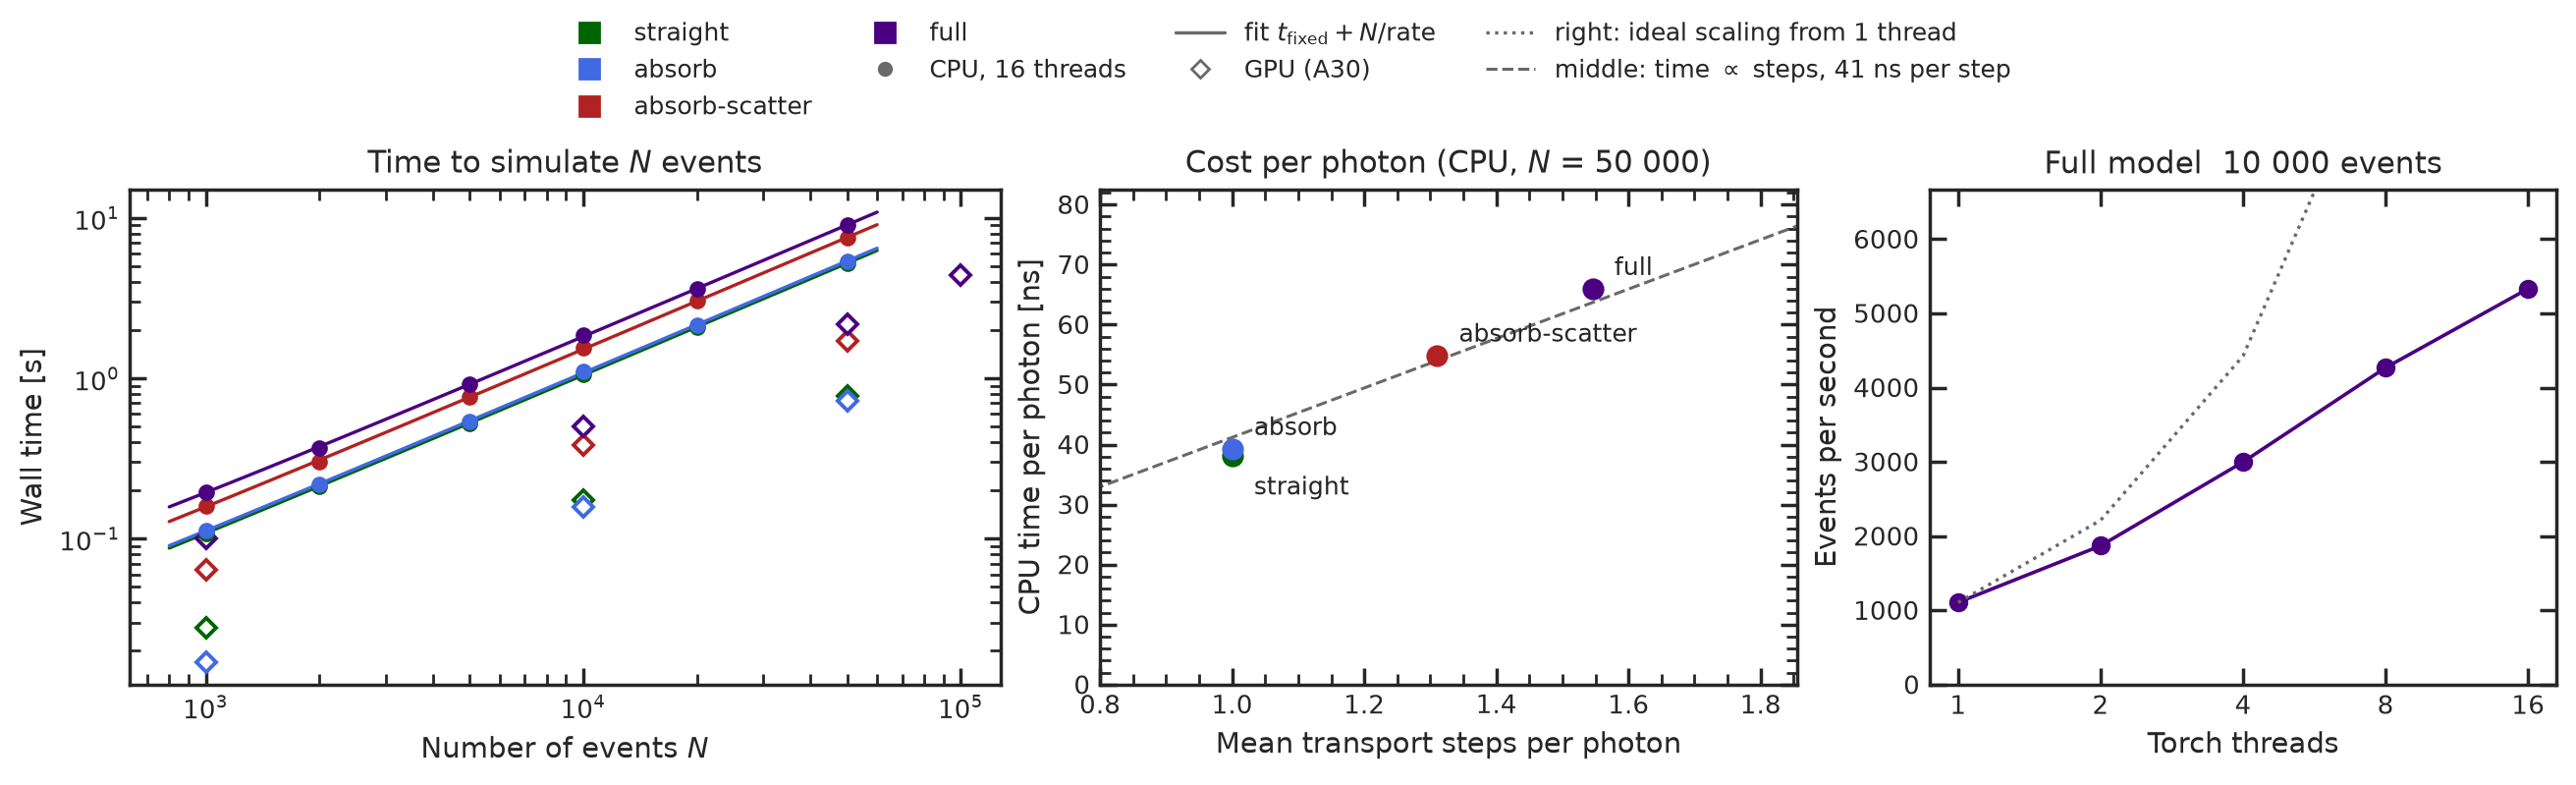

In [3]:
show("t0_2_timing")

- *End to end:* `flashsim generate -n 10000 --seed 1` took 3.30 s, of which 1.89 s simulation and 1.3 s to start
  Python and import torch.
- *Cost per photon:* 38.4, 39.6, 55.4 and 66.2 ns for straight, absorb, absorb-scatter and full, about 41 ns per
  photon-step (steps per photon 1.00, 1.00, 1.31, 1.55, counted on fully recorded paths). The full model is 1.73 times
  slower per photon than straight light, and every sample costs in proportion to its photons, Y E per event (2746 on
  average for the default prior).
- *Threads:* the full model runs at 1,100, 3,012 and 5,356 events/s with 1, 4 and 16 threads (speed-up 2.7 and
  4.9), so a laptop with a few cores is enough.
- *GPU:* 23,105 events/s for 50 000 events (measured once in a CUDA environment, `T0.2_gpu`); 1000-event runs are
  dominated by overhead (9,998 events/s).
- *Caveat:* the machine was shared (load average 9.9 rising to 14.4), and five runs of the same script gave
  4,122-5,491 events/s for the full model (`T0.2_history_rate_range`): the rates are indicative to about 25 %, the
  linear scaling and the ordering of the presets are robust.

*Figure:* `t0_2_timing`. *Numbers:* `results/T0.json` under `T0.2`, `T0.2_history`, `T0.2_gpu`, `T0.2_threads`,
`T0.2_derived` (`task0_timing.py`; last run of `run_all.sh` on 2026-10-21 13:49 UTC, 16 torch threads).

## T0.3 Inspect the file

`flashsim info FILE`, `python solutions/stage1_flash/task0_inspect.py` and `load(FILE)` all show the same content: four groups of
datasets and two JSON attributes, the complete configuration and the provenance. The 10 000 events of T0.2 take
2.64 MB.

| group | datasets (type) | shape |
|---|---|---|
| `/truth` | `event_id` (int64); `x`, `y` [m], `energy` [MeV], `t0` [ns] (float32) | (10000,) |
| `/response` | `charge` (int32); `time_mean`, `time_first` [ns] (float32, NaN where `charge == 0`) | (10000, 32) |
| `/photons` | `n_emitted`, `n_detected`, `n_absorbed_bulk`, `n_absorbed_wall`, `n_absorbed_sensor`, `n_lost`, `n_detected_direct`, `n_detected_scattered`, `n_detected_reflected`, `n_noise` (int32) | (10000,) |
| `/detector` | `sensor_x`, `sensor_y` [m], `sensor_phi` [rad] (float64) | (32,) |

**Details**

- *Root attributes:* `format_version` = 1, `n_events`, `config` (geometry, optics, readout, prior; here exactly the
  `full` preset: `load(path).config == preset("full")` is True) and `provenance` (seed, device, chunking, package and
  library versions, creation time, wall time and, for files written by `flashsim`, the preset, the overrides and the
  command).
- *Optional groups:* with `--save-hits --save-tracks 3` the file also gets `/hits` (one row per hit, 896.5 hits per
  event, 7 columns) and `/tracks` (300 recorded photons with 770 points for 3 events), and grows to 7.15 MB for
  1000 events.
- `git_commit` is `None` in these files because the working tree had no commit yet.

*Numbers:* `results/T0.json` under `T0.3`. No figure.